# Identificação do projeto

**Título do projeto:** Dengue no Brasil em 2026: pico de casos, gravidade e perfil dos pacientes

**Integrantes do grupo:** Bruna da Silva Carnelossi, João Pedro de Souza Quintiliano da Silva, João Victor Carvalho de Freitas, Matheus Henrique Heinzen

**Turma:** Sistemas de Informação • 6º período • Turma A GCL1 • Profª Marina de Lara

**Descrição breve do problema ou contexto:** a dengue é a arbovirose de maior impacto no Brasil e todo caso suspeito é de notificação compulsória ao SINAN. O projeto usa as notificações de 2026 para entender quando os casos se concentraram, onde e quais perfis de paciente evoluem para as formas graves da doença. No RA3, analisamos estatisticamente o conjunto preparado no RA1, interpretamos visualizações e testamos se é possível prever, no momento da notificação, quais pacientes serão hospitalizados.

Repositório: https://github.com/JoaoVictorCarvalho07/api-dados-abertos-saude

---

# RA3 – Análise, Visualização e Aprendizagem de Máquina

Utilize os dados preparados e processados nas etapas anteriores para realizar análises estatísticas, produzir visualizações, interpretar resultados e explorar uma aplicação simples de aprendizagem supervisionada.

## Preparação do ambiente

O RA3 parte do conjunto preparado no RA1 (`dados/preparados/dengue_brasil_2026.parquet`). Se o arquivo não existir, execute antes `ra1/ra1_dengue_2026.ipynb`. Bibliotecas: pandas, matplotlib e scikit-learn (versões fixas em `requirements.txt`). A população por UF vem do Censo 2022 do IBGE (tabela SIDRA 4709), salva em `ra3/populacao_uf_censo2022.csv`. As figuras são gravadas em `ra3/figuras/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

RAIZ = Path.cwd().parent
ARQUIVO_BRUTO = RAIZ / "DENGBR26.csv.zip"
ARQUIVO_PREPARADO = RAIZ / "dados" / "preparados" / "dengue_brasil_2026.parquet"
ARQUIVO_POPULACAO = RAIZ / "ra3" / "populacao_uf_censo2022.csv"
PASTA_FIGURAS = RAIZ / "ra3" / "figuras"
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)

SEMENTE = 42
ATRASO_EXTREMO_DIAS = 60
SEMANAS_COM_ATRASO_DE_DIGITACAO = 4

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def milhar(numero):
    return f"{numero:,.0f}".replace(",", ".")


def percentual(parte, total):
    return f"{parte / total:.1%}".replace(".", ",")


if not ARQUIVO_PREPARADO.exists():
    raise FileNotFoundError("Execute antes o notebook do RA1 (ra1/ra1_dengue_2026.ipynb), que gera o Parquet preparado.")

df = pd.read_parquet(ARQUIVO_PREPARADO)
print(f"Conjunto preparado no RA1: {milhar(len(df))} notificações e {df.shape[1]} colunas")
print(f"Datas de notificação: {df['dt_notificacao'].min().date()} a {df['dt_notificacao'].max().date()}")

Conjunto preparado no RA1: 470.221 notificações e 24 colunas
Datas de notificação: 2026-01-04 a 2026-10-04


## 3.1 – Análise Estatística Descritiva

- Aplique medidas de tendência central, como média e/ou mediana.
- Investigue a dispersão dos dados com amplitude, desvio-padrão ou outras medidas adequadas.
- Analise a distribuição dos valores.
- Interprete os resultados no contexto do problema escolhido.

Analisamos as duas variáveis numéricas centrais do projeto: a **idade** do paciente e o **atraso entre o início dos sintomas e a notificação** (em dias). Para cada uma calculamos medidas de tendência central (média, mediana, moda), de dispersão (desvio-padrão, amplitude, intervalo interquartil) e de forma da distribuição (quartis e assimetria). Depois olhamos a frequência das variáveis categóricas que definem gravidade: classificação final, hospitalização e faixa etária.

In [2]:
def medidas(serie):
    valores = serie.dropna().astype(float)
    q1, q3 = valores.quantile([0.25, 0.75])
    return {
        "n válidos": len(valores),
        "média": valores.mean(),
        "mediana": valores.median(),
        "moda": valores.mode().iloc[0],
        "desvio-padrão": valores.std(),
        "mínimo": valores.min(),
        "Q1 (25%)": q1,
        "Q3 (75%)": q3,
        "IQR (Q3 - Q1)": q3 - q1,
        "máximo": valores.max(),
        "amplitude": valores.max() - valores.min(),
        "assimetria": valores.skew(),
    }


atraso = df["atraso_notificacao_dias"]
tabela_medidas = pd.DataFrame(
    {
        "idade (anos)": medidas(df["idade_anos"]),
        "atraso sintomas → notificação (dias)": medidas(atraso),
        f"atraso até {ATRASO_EXTREMO_DIAS} dias": medidas(atraso.where(atraso <= ATRASO_EXTREMO_DIAS)),
    }
)
display(tabela_medidas)

extremos = int((atraso > ATRASO_EXTREMO_DIAS).sum())
print(f"Atrasos acima de {ATRASO_EXTREMO_DIAS} dias: {milhar(extremos)} ({percentual(extremos, atraso.notna().sum())} dos atrasos válidos)")
print(f"Notificadas no mesmo dia dos sintomas ou até 7 dias depois: {percentual(int((atraso <= 7).sum()), atraso.notna().sum())}")

,idade (anos),atraso sintomas → notificação (dias),atraso até 60 dias
n válidos,"470,206.00","470,221.00","467,779.00"
média,31.64,4.51,4.04
mediana,29.00,3.00,3.00
moda,19.00,3.00,3.00
desvio-padrão,19.15,8.63,5.20
mínimo,0.00,0.00,0.00
Q1 (25%),17.00,1.00,1.00
Q3 (75%),44.00,5.00,5.00
IQR (Q3 - Q1),27.00,4.00,4.00
máximo,120.00,238.00,60.00


Atrasos acima de 60 dias: 2.442 (0,5% dos atrasos válidos)
Notificadas no mesmo dia dos sintomas ou até 7 dias depois: 89,3%


In [3]:
def frequencia(coluna, incluir_vazio=True):
    contagem = df[coluna].astype("object").fillna("(não informado)") if incluir_vazio else df[coluna].dropna()
    contagem = contagem.value_counts()
    return pd.DataFrame({"notificações": contagem, "%": contagem / contagem.sum() * 100})


print("Classificação final")
display(frequencia("classificacao_final"))
print("Hospitalização")
display(frequencia("hospitalizado"))
print("Faixa etária")
display(frequencia("faixa_etaria").reindex(list(df["faixa_etaria"].cat.categories) + ["(não informado)"]).dropna())

confirmados = df[df["caso_grave"].notna()]
print(f"Entre os {milhar(len(confirmados))} casos confirmados de dengue (10, 11 e 12), "
      f"{percentual(int(confirmados['caso_grave'].sum()), len(confirmados))} são graves ou com sinais de alarme.")
hosp_info = df["hospitalizado"].dropna()
print(f"Entre as {milhar(len(hosp_info))} notificações com hospitalização informada, "
      f"{percentual(int(hosp_info.sum()), len(hosp_info))} foram hospitalizadas.")

Classificação final


,notificações,%
classificacao_final,,
Dengue,352663,75.00
Inconclusivo,69873,14.86
Sem classificação,34829,7.41
Dengue com sinais de alarme,12076,2.57
Dengue grave,780,0.17


Hospitalização


,notificações,%
hospitalizado,,
False,316933,67.40
(não informado),123598,26.29
True,29690,6.31


Faixa etária


,notificações,%
faixa_etaria,,
0-4,24882,5.29
5-14,67477,14.35
15-29,150538,32.01
30-44,110264,23.45
45-59,71703,15.25
60-74,34876,7.42
75+,10466,2.23
(não informado),15,0.00


Entre os 365.519 casos confirmados de dengue (10, 11 e 12), 3,5% são graves ou com sinais de alarme.
Entre as 346.623 notificações com hospitalização informada, 8,6% foram hospitalizadas.


**Resposta do grupo:**

- **Idade:** a média é 31,6 anos e a mediana 29 anos; metade dos pacientes tem entre 17 e 44 anos (IQR de 27 anos). O desvio-padrão (19,2 anos) e a amplitude de 0 a 120 anos mostram que a dengue atinge todas as idades, mas a distribuição é levemente assimétrica à direita (assimetria 0,55): há uma cauda de idosos que puxa a média para cima da mediana. A faixa mais notificada é a de 15 a 29 anos (32,0% das notificações), seguida de 30 a 44 anos (23,5%), ou seja, a dengue em 2026 atingiu principalmente adultos jovens em idade ativa.
- **Atraso até a notificação:** a mediana é de 3 dias e o IQR vai de 1 a 5 dias, mas a média é 4,5 dias, o desvio-padrão 8,6 dias e a amplitude chega a 238 dias. A assimetria (9,2) é muito forte: 89,3% dos casos são notificados em até 7 dias, e um grupo pequeno de 2.442 registros (0,5%) passa de 60 dias, o que no RA1 já tínhamos sinalizado como provável erro de digitação ou notificação tardia. Mesmo cortando esses extremos, a assimetria continua alta (4,6).
- **Por que mediana e IQR:** nas duas variáveis a média é puxada pela cauda (idosos, atrasos extremos). A mediana e o IQR não são afetados por poucos valores extremos, então descrevem melhor o paciente e o atraso "típicos". A média e o desvio-padrão ficam como complemento e servem justamente para mostrar o tamanho da cauda.
- **Gravidade:** 75,0% das notificações foram classificadas como dengue, 14,9% como inconclusivas e 7,4% ainda estão sem classificação. Entre os 365.519 casos confirmados, 3,5% evoluíram para dengue com sinais de alarme ou dengue grave. A hospitalização está informada em 346.623 notificações e, entre elas, 8,6% foram hospitalizadas; em 26,3% das notificações o campo está vazio.

**Significado para o problema:** a epidemia de 2026 é formada principalmente por casos leves em adultos jovens, notificados rapidamente (3 dias). Os casos graves e as hospitalizações são raros em proporção (3,5% e 8,6%), o que já antecipa uma dificuldade para o modelo de ML da seção 3.4: a classe que mais interessa é minoritária.

## 3.2 – Visualização e Interpretação dos Dados

- Produza pelo menos três visualizações adequadas ao problema.
- Identifique padrões, tendências, diferenças ou comportamentos relevantes.
- Explique o que cada visualização permite compreender.

**Não basta apresentar gráficos: é necessário interpretar os resultados.**

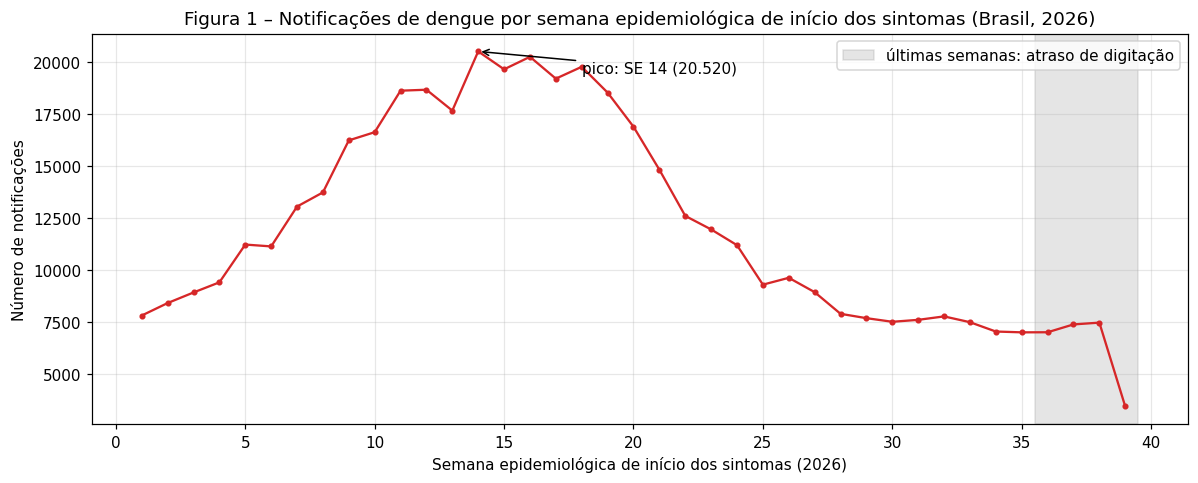

Semana de pico: 202614 com 20.520 notificações
Primeira semana (SE 01): 7.814 notificações
Menor valor entre as SE 11 e 19: 17.673
Média semanal: 12.057 | mediana semanal: 11.139
Semanas necessárias para somar 50% das notificações: 13 de 39
Semanas com mais notificações: 14, 16, 18, 15, 17
Últimas semanas:


,notificações
semana_epi_sintomas,
202634,7044
202635,7005
202636,7009
202637,7386
202638,7472
202639,3440


In [4]:
semanal = (
    df.dropna(subset=["semana_epi_sintomas"])
    .loc[lambda d: d["semana_epi_sintomas"].str.startswith("2026")]
    .groupby("semana_epi_sintomas")
    .size()
)
semanas = semanal.index.str[-2:].astype(int)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(semanas, semanal.values, marker="o", markersize=3, color="tab:red")
ultimas = semanas[-SEMANAS_COM_ATRASO_DE_DIGITACAO:]
ax.axvspan(ultimas.min() - 0.5, ultimas.max() + 0.5, color="grey", alpha=0.2, label="últimas semanas: atraso de digitação")
pico = semanal.idxmax()
ax.annotate(f"pico: SE {pico[-2:]} ({milhar(semanal.max())})", xy=(int(pico[-2:]), semanal.max()),
            xytext=(int(pico[-2:]) + 4, semanal.max() * 0.95), arrowprops={"arrowstyle": "->"})
ax.set_title("Figura 1 – Notificações de dengue por semana epidemiológica de início dos sintomas (Brasil, 2026)")
ax.set_xlabel("Semana epidemiológica de início dos sintomas (2026)")
ax.set_ylabel("Número de notificações")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "fig1_notificacoes_por_semana.png")
plt.show()

print(f"Semana de pico: {pico} com {milhar(semanal.max())} notificações")
print(f"Primeira semana (SE 01): {milhar(semanal.iloc[0])} notificações")
print(f"Menor valor entre as SE 11 e 19: {milhar(semanal.loc['202611':'202619'].min())}")
print(f"Média semanal: {milhar(semanal.mean())} | mediana semanal: {milhar(semanal.median())}")
top = semanal.sort_values(ascending=False)
acumulado = top.cumsum() / semanal.sum()
print(f"Semanas necessárias para somar 50% das notificações: {int((acumulado < 0.5).sum()) + 1} de {len(semanal)}")
print(f"Semanas com mais notificações: {', '.join(top.index[:5].str[-2:])}")
print("Últimas semanas:")
display(semanal.tail(6).to_frame("notificações"))

**Interpretação da Figura 1 (linha, tendência no tempo):** as notificações crescem de 7.814 na SE 1 até o pico na **semana epidemiológica 14 (início de abril), com 20.520 notificações**, e ficam acima de 17.000 por semana da SE 11 à SE 19. As cinco semanas com mais notificações são as SE 14 a 18, e apenas 13 das 39 semanas concentram metade de todas as notificações do ano: é o padrão sazonal da dengue, com pico no fim do verão e no outono. A partir de julho a curva se estabiliza em torno de 7.000 por semana. A queda na SE 39 (3.440) não é fim da epidemia: são as semanas mais recentes do arquivo, cujas fichas ainda estão sendo digitadas (atraso de notificação), por isso a área cinza deve ser lida com cuidado. Isso responde à P1 do projeto: o pico foi em abril.

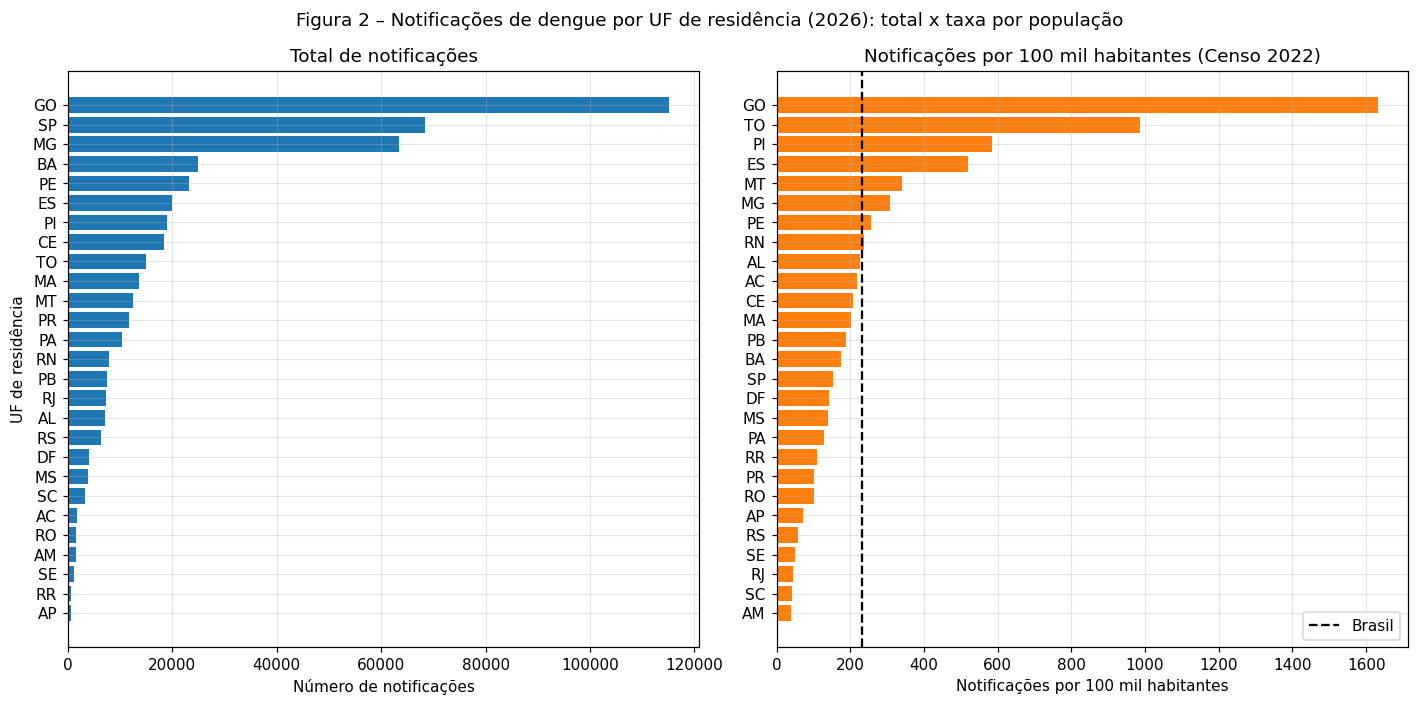

Taxa Brasil: 231.5 notificações por 100 mil habitantes
Participação das 3 UFs com mais notificações: 52,5%


,notificacoes,populacao_censo_2022,por_100_mil
uf,,,
GO,115161,7056495,"1,631.99"
SP,68330,44411238,153.86
MG,63367,20539989,308.51
BA,24856,14141626,175.76
PE,23254,9058931,256.70


,notificacoes,populacao_censo_2022,por_100_mil
uf,,,
GO,115161,7056495,"1,631.99"
TO,14918,1511460,986.99
PI,19089,3271199,583.55
ES,19944,3833712,520.23
MT,12447,3658649,340.21


,notificacoes,populacao_censo_2022,por_100_mil
uf,,,
AM,1585,3941613,40.21
SC,3287,7610361,43.19
RJ,7394,16055174,46.05


In [5]:
populacao = pd.read_csv(ARQUIVO_POPULACAO, dtype={"codigo_uf": str})
por_uf = (
    df["uf_residencia"].value_counts().rename("notificacoes").rename_axis("uf").reset_index()
    .merge(populacao[["uf", "populacao_censo_2022"]], on="uf")
)
por_uf["por_100_mil"] = por_uf["notificacoes"] / por_uf["populacao_censo_2022"] * 100_000

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6.5))
absoluto = por_uf.sort_values("notificacoes")
ax1.barh(absoluto["uf"], absoluto["notificacoes"], color="tab:blue")
ax1.set_title("Total de notificações")
ax1.set_xlabel("Número de notificações")
ax1.set_ylabel("UF de residência")
taxa = por_uf.sort_values("por_100_mil")
ax2.barh(taxa["uf"], taxa["por_100_mil"], color="tab:orange")
ax2.axvline(df["uf_residencia"].notna().sum() / populacao["populacao_censo_2022"].sum() * 100_000,
            color="black", linestyle="--", label="Brasil")
ax2.set_title("Notificações por 100 mil habitantes (Censo 2022)")
ax2.set_xlabel("Notificações por 100 mil habitantes")
ax2.legend()
fig.suptitle("Figura 2 – Notificações de dengue por UF de residência (2026): total x taxa por população")
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "fig2_notificacoes_por_uf.png")
plt.show()

taxa_brasil = df["uf_residencia"].notna().sum() / populacao["populacao_censo_2022"].sum() * 100_000
print(f"Taxa Brasil: {taxa_brasil:.1f} notificações por 100 mil habitantes")
print(f"Participação das 3 UFs com mais notificações: {percentual(absoluto['notificacoes'].tail(3).sum(), por_uf['notificacoes'].sum())}")
display(por_uf.sort_values("notificacoes", ascending=False).head(5).set_index("uf"))
display(por_uf.sort_values("por_100_mil", ascending=False).head(5).set_index("uf"))
display(por_uf.sort_values("por_100_mil").head(3).set_index("uf"))

**Interpretação da Figura 2 (barras, comparação entre UFs):** em números absolutos, Goiás (115.161), São Paulo (68.330) e Minas Gerais (63.367) somam 52,5% das notificações. Mas número absoluto mistura tamanho da população com intensidade da epidemia, por isso o painel da direita divide pela população do Censo 2022. Na taxa, São Paulo cai para 153,9 notificações por 100 mil habitantes, abaixo da taxa nacional (231,5), enquanto Goiás (1.632 por 100 mil, sete vezes a média do país), Tocantins (987), Piauí (584) e Espírito Santo (520) aparecem como os estados mais afetados proporcionalmente. Amazonas (40,2), Santa Catarina (43,2) e Rio de Janeiro (46,1) têm as menores taxas. A comparação mostra por que a taxa por habitante é a medida adequada para dizer "onde a dengue foi mais intensa", e que Goiás foi o epicentro de 2026 nas duas medidas.

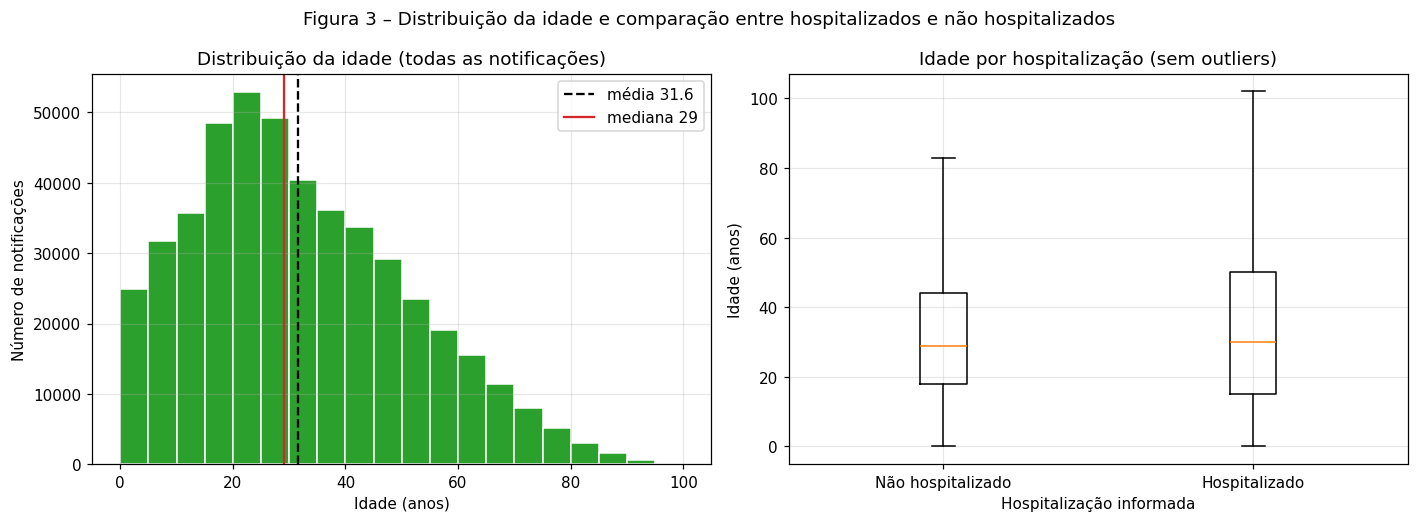

,Não hospitalizado,Hospitalizado
n válidos,"316,925.00","29,690.00"
média,31.68,33.72
mediana,29.00,30.00
Q1 (25%),18.00,15.00
Q3 (75%),44.00,50.00
IQR (Q3 - Q1),26.00,35.00


In [6]:
com_hosp = df.dropna(subset=["hospitalizado", "idade_anos"])
grupos = {
    "Não hospitalizado": com_hosp.loc[~com_hosp["hospitalizado"].astype(bool), "idade_anos"].astype(float),
    "Hospitalizado": com_hosp.loc[com_hosp["hospitalizado"].astype(bool), "idade_anos"].astype(float),
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
ax1.hist(df["idade_anos"].dropna().astype(float), bins=range(0, 105, 5), color="tab:green", edgecolor="white")
ax1.axvline(df["idade_anos"].mean(), color="black", linestyle="--", label=f"média {df['idade_anos'].mean():.1f}")
ax1.axvline(df["idade_anos"].median(), color="tab:red", label=f"mediana {df['idade_anos'].median():.0f}")
ax1.set_title("Distribuição da idade (todas as notificações)")
ax1.set_xlabel("Idade (anos)")
ax1.set_ylabel("Número de notificações")
ax1.legend()
ax2.boxplot(list(grupos.values()), tick_labels=list(grupos.keys()), showfliers=False)
ax2.set_title("Idade por hospitalização (sem outliers)")
ax2.set_xlabel("Hospitalização informada")
ax2.set_ylabel("Idade (anos)")
fig.suptitle("Figura 3 – Distribuição da idade e comparação entre hospitalizados e não hospitalizados")
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "fig3_idade_hospitalizacao.png")
plt.show()

display(pd.DataFrame({nome: medidas(serie) for nome, serie in grupos.items()}).loc[["n válidos", "média", "mediana", "Q1 (25%)", "Q3 (75%)", "IQR (Q3 - Q1)"]])

**Interpretação da Figura 3 (histograma e boxplot, distribuição):** o histograma confirma a assimetria à direita vista na 3.1: a maior concentração está entre 15 e 30 anos e a frequência cai continuamente após os 40, com a média (31,6) à direita da mediana (29). No boxplot, a mediana de idade é quase igual entre hospitalizados (30 anos) e não hospitalizados (29 anos), mas a **caixa dos hospitalizados é bem mais larga** (IQR de 35 anos, de 15 a 50, contra 26 anos, de 18 a 44). Ou seja, a hospitalização não está ligada a "ser mais velho" de forma linear: ela se espalha para os dois extremos, crianças e idosos. A Figura 4 detalha esse efeito.

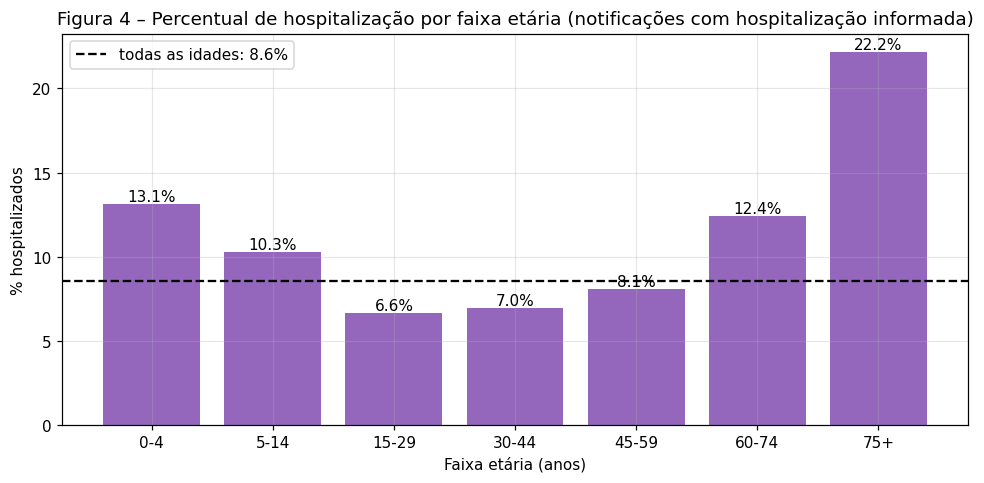

,notificacoes,hospitalizados,% hospitalizados
faixa_etaria,,,
0-4,17610,2311,13.12
5-14,48960,5022,10.26
15-29,111020,7379,6.65
30-44,81823,5697,6.96
45-59,53191,4293,8.07
60-74,26111,3238,12.40
75+,7900,1750,22.15


In [7]:
taxa_faixa = (
    df.dropna(subset=["hospitalizado", "faixa_etaria"])
    .groupby("faixa_etaria", observed=True)["hospitalizado"]
    .agg(notificacoes="size", hospitalizados="sum")
)
taxa_faixa["% hospitalizados"] = taxa_faixa["hospitalizados"] / taxa_faixa["notificacoes"] * 100
geral = df["hospitalizado"].dropna().mean() * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
barras = ax.bar(taxa_faixa.index.astype(str), taxa_faixa["% hospitalizados"], color="tab:purple")
ax.bar_label(barras, fmt="%.1f%%")
ax.axhline(geral, color="black", linestyle="--", label=f"todas as idades: {geral:.1f}%")
ax.set_title("Figura 4 – Percentual de hospitalização por faixa etária (notificações com hospitalização informada)")
ax.set_xlabel("Faixa etária (anos)")
ax.set_ylabel("% hospitalizados")
ax.legend()
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "fig4_hospitalizacao_por_faixa.png")
plt.show()
display(taxa_faixa)

**Interpretação da Figura 4 (barras, proporção por grupo):** o percentual de hospitalização tem forma de "U". Ele é de 13,1% em crianças de 0 a 4 anos e 10,3% de 5 a 14 anos, cai para cerca de 7% entre 15 e 44 anos (6,7% e 7,0%), e volta a subir a partir dos 45 anos: 8,1% (45–59), 12,4% (60–74) e 22,2% acima de 75 anos, mais que o dobro da média geral (8,6%). Os adultos jovens são a maioria dos casos (Figura 3), mas os extremos de idade são os que mais internam, o que responde em parte à P3 do projeto e orienta onde concentrar atenção na rede de saúde. Para o modelo, isso significa que a relação entre idade e hospitalização não é linear.

**Resposta do grupo:**

- **Figura 1 (tempo):** pico na SE 14 (20.520 notificações), com metade do ano concentrada em 13 semanas entre março e maio; a queda final é atraso de digitação, não fim da epidemia.
- **Figura 2 (espaço):** Goiás lidera em número absoluto e em taxa (1.632 por 100 mil). São Paulo é o 2º em número absoluto, mas fica abaixo da média nacional na taxa: comparar UFs só faz sentido por habitante.
- **Figura 3 (distribuição da idade):** pacientes concentrados em adultos jovens; os hospitalizados têm idade muito mais dispersa (IQR 35 x 26 anos).
- **Figura 4 (risco por idade):** hospitalização em "U", maior em crianças até 4 anos (13,1%) e idosos acima de 75 (22,2%).

Juntas, as visualizações respondem **quando** (abril), **onde** (Goiás, Tocantins, Piauí, Espírito Santo) e **quem** (extremos de idade internam mais) para o problema do projeto.

## 3.3 – Amostragem e Representatividade

- Descreva a origem e a abrangência dos dados.
- Analise em que medida o conjunto representa o contexto investigado.
- Identifique possíveis vieses ou limitações.
- Descreva o procedimento de amostragem, caso tenha sido utilizado.

Não é obrigatório implementar uma técnica de amostragem. Documente a análise principalmente em células Markdown; a célula de código abaixo é opcional, para análises complementares.

**Resposta do grupo:**

**Origem.** Os dados são o arquivo público `DENGBR26.csv.zip` do Sinan/Dengue, publicado no Portal de Dados Abertos do SUS. O Sinan é um sistema de **vigilância passiva**: o registro só existe quando um serviço de saúde atende o paciente, suspeita de dengue e preenche a ficha de notificação compulsória. Cada linha é uma **notificação**, não um caso confirmado nem uma pessoa.

**Abrangência.** Todas as 27 UFs, com notificações de 04/01 a 04/10/2026 (470.221 registros após a preparação do RA1). Não usamos amostragem nas análises descritivas e nas visualizações: trabalhamos com a população inteira de notificações do arquivo. No modelo da seção 3.4 também usamos todos os registros com hospitalização informada; a única seleção é a divisão aleatória e estratificada 80/20 entre treino e teste.

**O conjunto representa o problema?** Representa bem a **demanda que chega à rede de saúde** e a dinâmica temporal e espacial da epidemia, que é o foco das perguntas P1–P3. Não representa todas as infecções de dengue da população, por estes motivos:

1. **Subnotificação:** infecções assintomáticas ou leves sem procura por atendimento nunca entram no Sinan. Os números são um piso, não o total real.
2. **Diferença entre estados:** a qualidade e a intensidade da notificação variam por UF. Taxas muito baixas (AM, SC, RJ) podem refletir menos dengue ou menos notificação; a taxa por 100 mil corrige o tamanho da população, mas não esse viés.
3. **Atraso de digitação e de encerramento:** as últimas semanas estão incompletas (Figura 1) e a proporção de notificações sem classificação final sobe de 1,1% nos casos de junho para 35,5% em agosto, 65,9% em setembro e 86,2% em outubro (tabela abaixo). Conclusões sobre o segundo semestre são provisórias.
4. **Campos vazios:** a hospitalização está vazia em 26,3% das notificações e a evolução em 28,6%. A falta não é aleatória: varia de 19,0% no Centro-Oeste a 46,2% no Sul. Por isso, o percentual de 8,6% de hospitalizados e o modelo valem para as notificações em que o campo foi preenchido.
5. **Recorte do arquivo público:** o arquivo não contém nenhuma notificação com classificação "descartado" (código 5), e 14,9% estão como inconclusivas. A base, portanto, é formada por casos confirmados, inconclusivos ou ainda em investigação, não por todos os suspeitos notificados.
6. **Possíveis duplicatas:** sem identificador de paciente, as 5.797 linhas marcadas como possível duplicata no RA1 (`possivel_duplicata`) foram mantidas; uma pessoa pode aparecer mais de uma vez.

O resultado é adequado para descrever o padrão da epidemia notificada e comparar grupos, mas números absolutos e regiões com muito campo vazio devem ser interpretados como estimativas conservadoras.

In [8]:
colunas = ["hospitalizado", "classificacao_final", "sexo", "idade_anos", "dt_sintomas", "uf_residencia", "diabetes", "hipertensao", "evolucao"]
completude = pd.DataFrame({
    "% vazio": df[colunas].isna().mean() * 100,
})
completude.loc["classificacao_final", "% vazio"] = (df["classificacao_final"] == "Sem classificação").mean() * 100
display(completude.sort_values("% vazio", ascending=False))

print("Hospitalização sem informação por região de residência (%):")
display((df.groupby("regiao_residencia", observed=True)["hospitalizado"].apply(lambda s: s.isna().mean() * 100)).round(1).to_frame("% vazio"))

mensal = df.groupby("mes_sintomas")["classificacao_final"].apply(lambda s: (s == "Sem classificação").mean() * 100)
print("Notificações ainda sem classificação final, por mês de início dos sintomas (%):")
display(mensal.round(1).to_frame("% sem classificação").tail(6))

print(f"Linhas marcadas como possível duplicata no RA1 (mesma chave de pessoa, local e datas): {milhar(int(df['possivel_duplicata'].sum()))}")
descartados = int((df["classificacao_final"] == "Descartado").sum())
inconclusivos = int((df["classificacao_final"] == "Inconclusivo").sum())
print(f"Notificações descartadas (código 5) no arquivo público: {milhar(descartados)}")
print(f"Notificações inconclusivas (código 8): {milhar(inconclusivos)} ({percentual(inconclusivos, len(df))})")

,% vazio
evolucao,28.59
hospitalizado,26.29
classificacao_final,7.41
hipertensao,3.17
diabetes,3.17
sexo,0.06
idade_anos,0.00
dt_sintomas,0.00
uf_residencia,0.00


Hospitalização sem informação por região de residência (%):


,% vazio
regiao_residencia,
Centro-Oeste,19.00
Nordeste,37.60
Norte,29.20
Sudeste,20.50
Sul,46.20


Notificações ainda sem classificação final, por mês de início dos sintomas (%):


,% sem classificação
mes_sintomas,
2026-05,0.50
2026-06,1.10
2026-07,3.80
2026-08,35.50
2026-09,65.90
2026-10,86.20


Linhas marcadas como possível duplicata no RA1 (mesma chave de pessoa, local e datas): 5.797
Notificações descartadas (código 5) no arquivo público: 0
Notificações inconclusivas (código 8): 69.873 (14,9%)


A tabela confirma os pontos 3, 4 e 5: completude alta nas variáveis de pessoa, lugar e tempo (sexo, idade, data e UF quase sem vazios) e baixa nas variáveis de desfecho (hospitalização e evolução), justamente as que dependem de acompanhamento do caso.

## 3.4 – Aplicação de Machine Learning

Implemente uma aplicação simples de aprendizagem supervisionada. Escolha **classificação OU regressão**, conforme a natureza do problema.

1. **Problema preditivo:** defina o que a equipe pretende prever.
2. **Entradas e alvo:** identifique as características (*features*) e a variável-alvo (*target*).
3. **Treinamento e teste:** separe os dados para treinar e avaliar o modelo.
4. **Treinamento e previsões:** treine o modelo escolhido e realize previsões.
5. **Avaliação:** utilize pelo menos uma métrica adequada ao problema.
6. **Interpretação:** explique o significado dos resultados obtidos.

A equipe pode utilizar qualquer algoritmo ou ferramenta adequada; **não é obrigatório utilizar KNN ou regressão linear**. Não é necessário implementar aprendizagem online.

Se o dataset original não for adequado à aprendizagem supervisionada, a equipe poderá utilizar outro conjunto de dados nesta seção, justificando a escolha.

**Decisões do grupo:**

- **Problema preditivo:** no momento da notificação, prever se o paciente **será hospitalizado**. É um problema de **classificação binária** com utilidade prática: sinalizar cedo os pacientes de maior risco para priorizar acompanhamento e planejar leitos.
- **Target:** `hospitalizado` (campo `HOSPITALIZ`: 1 = sim, 2 = não). Usamos só as 346.623 notificações com o campo preenchido; os 123.598 vazios ou "ignorado" saem, porque não sabemos a resposta certa deles. A classe positiva é minoritária (8,6%).
- **Features (31), só informações disponíveis no momento da notificação:** idade (em décadas), atraso sintomas → notificação (limitado a 60 dias), sexo feminino, gestante (`CS_GESTANT` 1 a 4), 14 sinais e sintomas da ficha (`FEBRE`, `MIALGIA`, `CEFALEIA`, `EXANTEMA`, `VOMITO`, `NAUSEA`, `DOR_COSTAS`, `CONJUNTVIT`, `ARTRITE`, `ARTRALGIA`, `PETEQUIA_N`, `LEUCOPENIA`, `LACO`, `DOR_RETRO`), 7 comorbidades (`DIABETES`, `HEMATOLOG`, `HEPATOPAT`, `RENAL`, `HIPERTENSA`, `ACIDO_PEPT`, `AUTO_IMUNE`), um indicador de ficha clínica vazia e a região de residência (5 colunas *dummy*). Sintomas e comorbidades viram 1 quando o campo é "sim" e 0 caso contrário. Como o Parquet do RA1 guardou só as colunas das perguntas P1–P3, essas colunas são lidas do arquivo bruto e ligadas pela posição original da linha (`id_registro`).
- **Colunas excluídas para evitar vazamento de dados (*data leakage*):** tudo o que só é conhecido **depois** da hospitalização ou que é consequência dela: `DT_INTERNA` (data da internação), `EVOLUCAO` e `DT_OBITO` (desfecho), `CLASSI_FIN` e `CRITERIO` (classificação final, que usa a gravidade observada durante o acompanhamento), `DT_ENCERRA`, os sinais de alarme `ALRM_*`/`DT_ALRM` e de gravidade `GRAV_*`/`DT_GRAV` (registrados durante a evolução clínica e muitas vezes já no hospital) e os resultados de exames laboratoriais (sorologia, NS1, PCR, sorotipo), que costumam sair depois do atendimento inicial. Se essas colunas entrassem, o modelo "acertaria" olhando para a resposta, e o resultado não serviria para prever nada.
- **Separação:** 80% treino (277.298) e 20% teste (69.325), **estratificada** pelo target (as duas partes ficam com 8,6% de hospitalizados) e com semente fixa (`random_state=42`) para ser reproduzível.
- **Modelos:** (1) *baseline* que sempre prevê a classe majoritária, como referência mínima; (2) **regressão logística** com `class_weight="balanced"`, modelo principal por ser simples e interpretável (cada coeficiente vira uma razão de chances); (3) **árvore de decisão** rasa (profundidade 6), que captura relações não lineares como o "U" da idade. O `class_weight="balanced"` dá mais peso aos hospitalizados no treino; sem ele, o modelo aprenderia a dizer sempre "não".
- **Métricas:** como as classes são desbalanceadas, a acurácia engana (o *baseline* acerta 91% sem identificar ninguém). Usamos **recall** (dos hospitalizados reais, quantos o modelo encontra), **precisão** (dos alertas, quantos estavam certos), **F1** (equilíbrio entre os dois) e **ROC-AUC** (capacidade de ordenar pacientes por risco, independente do limiar), além da matriz de confusão. A métrica principal é o recall, porque deixar de sinalizar um paciente que vai internar é o erro mais caro.

In [9]:
SINTOMAS = ["FEBRE", "MIALGIA", "CEFALEIA", "EXANTEMA", "VOMITO", "NAUSEA", "DOR_COSTAS", "CONJUNTVIT",
            "ARTRITE", "ARTRALGIA", "PETEQUIA_N", "LEUCOPENIA", "LACO", "DOR_RETRO"]
COMORBIDADES = ["DIABETES", "HEMATOLOG", "HEPATOPAT", "RENAL", "HIPERTENSA", "ACIDO_PEPT", "AUTO_IMUNE"]

# O Parquet do RA1 guarda só as colunas das perguntas P1–P3. Sintomas, comorbidades e gestação são
# lidos do arquivo bruto e ligados pela posição da linha (id_registro), que o RA1 preservou para isso.
bruto = pd.read_csv(ARQUIVO_BRUTO, usecols=SINTOMAS + COMORBIDADES + ["CS_GESTANT"], dtype="string")
clinico = bruto.loc[df["id_registro"]].reset_index(drop=True)

base = df.reset_index(drop=True).join(clinico)
base = base[base["hospitalizado"].notna()].copy()

X = pd.DataFrame(index=base.index)
X["idade_decadas"] = base["idade_anos"].astype(float).fillna(base["idade_anos"].median()) / 10
X["atraso_dias"] = base["atraso_notificacao_dias"].astype(float).clip(0, ATRASO_EXTREMO_DIAS).fillna(base["atraso_notificacao_dias"].median())
X["sexo_feminino"] = (base["sexo"] == "Feminino").astype(int)
X["gestante"] = base["CS_GESTANT"].isin(["1", "2", "3", "4"]).astype(int)
for coluna in SINTOMAS + COMORBIDADES:
    X[coluna.lower()] = (base[coluna] == "1").astype(int)
X["ficha_clinica_vazia"] = base["FEBRE"].isna().astype(int)
X = X.join(pd.get_dummies(base["regiao_residencia"].astype("object").fillna("Sem região"), prefix="regiao", dtype=int))
y = base["hospitalizado"].astype(int)

print(f"Registros com hospitalização informada: {milhar(len(X))} (de {milhar(len(df))})")
print(f"Features: {X.shape[1]}")
print(f"Hospitalizados (classe positiva): {milhar(y.sum())} ({percentual(y.sum(), len(y))})")
print(list(X.columns))

Registros com hospitalização informada: 346.623 (de 470.221)
Features: 31
Hospitalizados (classe positiva): 29.690 (8,6%)
['idade_decadas', 'atraso_dias', 'sexo_feminino', 'gestante', 'febre', 'mialgia', 'cefaleia', 'exantema', 'vomito', 'nausea', 'dor_costas', 'conjuntvit', 'artrite', 'artralgia', 'petequia_n', 'leucopenia', 'laco', 'dor_retro', 'diabetes', 'hematolog', 'hepatopat', 'renal', 'hipertensa', 'acido_pept', 'auto_imune', 'ficha_clinica_vazia', 'regiao_Centro-Oeste', 'regiao_Nordeste', 'regiao_Norte', 'regiao_Sudeste', 'regiao_Sul']


In [10]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMENTE
)
print(f"Treino: {milhar(len(X_treino))} registros ({percentual(y_treino.sum(), len(y_treino))} hospitalizados)")
print(f"Teste:  {milhar(len(X_teste))} registros ({percentual(y_teste.sum(), len(y_teste))} hospitalizados)")

modelos = {
    "Baseline (classe majoritária)": DummyClassifier(strategy="most_frequent"),
    "Regressão logística (balanced)": LogisticRegression(class_weight="balanced", max_iter=2000),
    "Árvore de decisão (prof. 6, balanced)": DecisionTreeClassifier(max_depth=6, min_samples_leaf=200, class_weight="balanced", random_state=SEMENTE),
}
previsoes, probabilidades = {}, {}
for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    previsoes[nome] = modelo.predict(X_teste)
    probabilidades[nome] = modelo.predict_proba(X_teste)[:, 1]
# Teste de sensibilidade: leucopenia depende de hemograma, que pode ter sido feito já no atendimento hospitalar.
sem_leucopenia = LogisticRegression(class_weight="balanced", max_iter=2000)
sem_leucopenia.fit(X_treino.drop(columns="leucopenia"), y_treino)
nome_sens = "Regressão logística sem leucopenia"
previsoes[nome_sens] = sem_leucopenia.predict(X_teste.drop(columns="leucopenia"))
probabilidades[nome_sens] = sem_leucopenia.predict_proba(X_teste.drop(columns="leucopenia"))[:, 1]
print("Modelos treinados e previsões feitas no conjunto de teste.")

Treino: 277.298 registros (8,6% hospitalizados)
Teste:  69.325 registros (8,6% hospitalizados)


Modelos treinados e previsões feitas no conjunto de teste.


### Avaliação e interpretação

Compare as previsões com os valores reais do conjunto de teste, calcule a métrica escolhida e interprete o resultado no contexto do problema preditivo.

,acurácia,precisão,recall (sensibilidade),F1,ROC-AUC
Baseline (classe majoritária),0.914,0.000,0.000,0.000,0.500
Regressão logística (balanced),0.699,0.174,0.669,0.276,0.747
"Árvore de decisão (prof. 6, balanced)",0.678,0.168,0.698,0.271,0.744
Regressão logística sem leucopenia,0.680,0.163,0.663,0.262,0.730


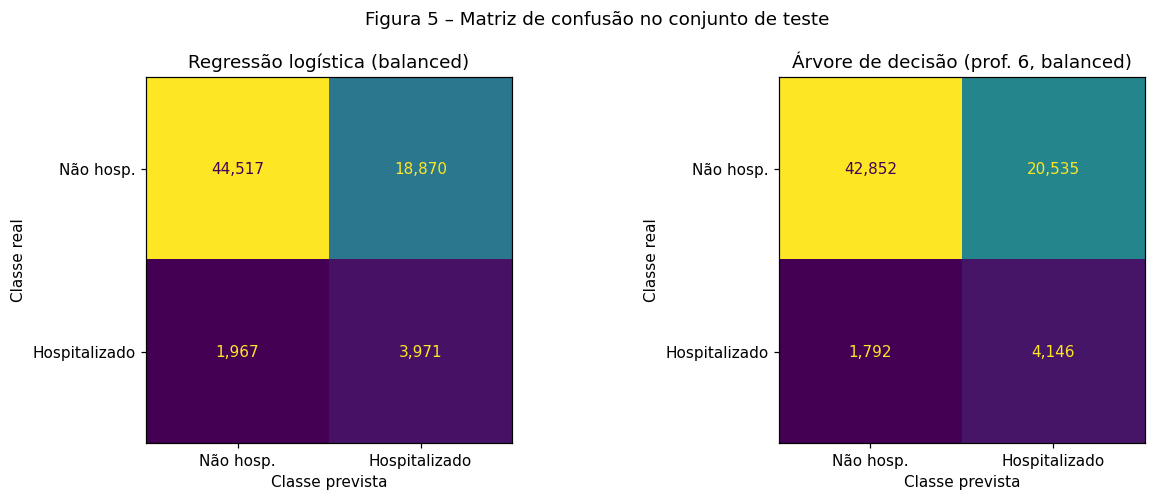

Regressão logística: VP=3.971 FN=1.967 FP=18.870 VN=44.517


In [11]:
resultados = pd.DataFrame({
    nome: {
        "acurácia": accuracy_score(y_teste, previsoes[nome]),
        "precisão": precision_score(y_teste, previsoes[nome], zero_division=0),
        "recall (sensibilidade)": recall_score(y_teste, previsoes[nome]),
        "F1": f1_score(y_teste, previsoes[nome]),
        "ROC-AUC": roc_auc_score(y_teste, probabilidades[nome]),
    }
    for nome in previsoes
}).T
display(resultados.style.format("{:.3f}"))

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, nome in zip(eixos, ["Regressão logística (balanced)", "Árvore de decisão (prof. 6, balanced)"]):
    ConfusionMatrixDisplay(confusion_matrix(y_teste, previsoes[nome]), display_labels=["Não hosp.", "Hospitalizado"]).plot(ax=ax, colorbar=False, values_format=",d")
    ax.set_title(nome)
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")
    ax.grid(False)
fig.suptitle("Figura 5 – Matriz de confusão no conjunto de teste")
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "fig5_matriz_confusao.png")
plt.show()

vn, fp, fn, vp = confusion_matrix(y_teste, previsoes["Regressão logística (balanced)"]).ravel()
print(f"Regressão logística: VP={milhar(vp)} FN={milhar(fn)} FP={milhar(fp)} VN={milhar(vn)}")

In [12]:
logistica = modelos["Regressão logística (balanced)"]
razao_chances = pd.Series(np.exp(logistica.coef_[0]), index=X.columns, name="razão de chances").sort_values()
print("Features que mais aumentam a chance de hospitalização (razão de chances > 1):")
display(razao_chances.tail(8).sort_values(ascending=False).to_frame())
print("Features associadas a menor chance (razão de chances < 1):")
display(razao_chances.head(5).to_frame())
print("Variáveis numéricas e sexo:")
display(razao_chances[["idade_decadas", "atraso_dias", "sexo_feminino"]].to_frame())

Features que mais aumentam a chance de hospitalização (razão de chances > 1):


,razão de chances
leucopenia,4.08
gestante,2.62
regiao_Nordeste,1.91
auto_imune,1.90
renal,1.84
hematolog,1.75
vomito,1.72
diabetes,1.65


Features associadas a menor chance (razão de chances < 1):


,razão de chances
regiao_Sudeste,0.56
cefaleia,0.59
regiao_Centro-Oeste,0.63
acido_pept,0.76
conjuntvit,0.77


Variáveis numéricas e sexo:


,razão de chances
idade_decadas,1.07
atraso_dias,1.04
sexo_feminino,0.90


**Resposta do grupo:**

- **Comparação com o *baseline*:** o *baseline* tem 91,4% de acurácia, mas recall 0 e ROC-AUC 0,50: nunca identifica um hospitalizado. A **regressão logística** encontra **66,9% dos hospitalizados** do teste (recall 0,669), com ROC-AUC de **0,747**, precisão de 0,174 e F1 de 0,276. A árvore de decisão tem desempenho praticamente igual (recall 0,698, F1 0,271, ROC-AUC 0,744), então ficamos com a logística, que é mais simples de explicar.
- **Lendo a matriz de confusão (logística):** dos 5.938 hospitalizados do teste, o modelo sinalizou 3.971 (verdadeiros positivos) e deixou passar 1.967 (falsos negativos). Em troca, gerou 18.870 alarmes falsos entre os 63.387 não hospitalizados. Por isso a precisão é baixa: de cada 100 pacientes sinalizados, cerca de 17 são realmente internados, o dobro da taxa geral de 8,6%.
- **O que o modelo aprendeu (razões de chances):** leucopenia (4,08 vezes a chance), gestação (2,62), residir no Nordeste (1,91), doença autoimune (1,90), doença renal (1,84), doença hematológica (1,75), vômito (1,72) e diabetes (1,65) aumentam a chance de hospitalização, o que é coerente com os grupos de risco descritos pelo Ministério da Saúde. Residir no Sudeste (0,56) ou no Centro-Oeste (0,63) e ter cefaleia (0,59), um sintoma típico de quadros leves, reduzem a chance. A idade quase não aparece na logística (1,07 por década) porque o efeito real é em "U" (Figura 4) e uma reta não consegue representá-lo.
- **Teste de sensibilidade:** a leucopenia depende de hemograma, que pode ter sido feito já durante o atendimento hospitalar. Sem essa variável, o modelo perde pouco (ROC-AUC 0,730, recall 0,663), então o resultado não depende só dela.
- **Interpretação e limitações:** um ROC-AUC de 0,75 indica capacidade **moderada** de separar quem interna de quem não interna usando apenas a ficha de notificação. O modelo serve como **triagem**, para priorizar quem acompanhar, e não como diagnóstico: a decisão de internar depende de exames, sinais de alarme e de leito disponível, que não estão na notificação. O peso das regiões também mostra que o modelo aprende diferenças de prática e de preenchimento entre estados, não só de risco clínico, e os 26,3% de campos vazios de hospitalização limitam a generalização.

## 3.5 – Conclusões do RA3

Apresente brevemente:

- As principais descobertas das análises estatísticas.
- Os resultados mais relevantes das visualizações.
- A interpretação do desempenho do modelo de Machine Learning.
- As limitações identificadas.
- A relação dos resultados com o problema definido no projeto.

**Conclusões do grupo:**

1. **Principais descobertas estatísticas:** o paciente típico de dengue em 2026 é um adulto jovem (mediana de 29 anos, metade entre 17 e 44) notificado em cerca de 3 dias após os sintomas. As duas variáveis são assimétricas à direita, por isso mediana e IQR descrevem melhor que média e desvio-padrão. Formas graves (3,5% dos confirmados) e hospitalizações (8,6% das notificações informadas) são minoria.
2. **Visualizações:** a epidemia teve pico na SE 14 (abril), com metade das notificações em 13 semanas; Goiás foi o epicentro (115.161 notificações e 1.632 por 100 mil habitantes, sete vezes a taxa nacional), seguido por Tocantins, Piauí e Espírito Santo na taxa; o risco de internação tem forma de "U", maior em crianças pequenas e principalmente em idosos acima de 75 anos (22,2%).
3. **Modelo de ML:** a regressão logística, usando só informações da notificação, encontra cerca de dois terços dos pacientes que serão hospitalizados (recall 0,67) com ROC-AUC de 0,75, bem acima do *baseline* (0,50). O desempenho é moderado e a precisão é baixa (0,17), o que é esperado com uma classe rara e poucas variáveis clínicas. As variáveis de maior peso (leucopenia, gestação, comorbidades, vômito) coincidem com os grupos de risco conhecidos, o que dá confiança de que o modelo aprendeu padrões reais e não vazamento.
4. **Limitações:** vigilância passiva com subnotificação; diferenças de notificação entre UFs; últimas semanas e classificações ainda incompletas; 26,3% de hospitalização e 28,6% de evolução sem informação, de forma desigual entre regiões; arquivo público sem casos descartados; e possíveis duplicatas sem identificador de paciente.
5. **Relação com o problema do projeto:** os resultados respondem às três perguntas centrais. **Quando:** o pico foi em abril (P1). **Onde:** Goiás concentrou mais casos, em número e por habitante (P1). **Quem:** extremos de idade, gestantes e pessoas com comorbidades têm mais chance de internar (P3). Na prática, isso indica que o planejamento de leitos e campanhas deve antecipar o período de março a maio e priorizar esses grupos, e que um modelo simples de triagem na notificação pode ajudar a sinalizar pacientes de risco, desde que a qualidade de preenchimento das fichas melhore.